=== RESIDENTIAL 8 kWp PV + LFP BESS SIZING & PAYBACK ACROSS EU MARKETS ===
          Market  Battery (kWh)  Self-Sufficiency (%)  Self-Consumption (%)  CapEx (€)  Annual Savings (€/yr)  Simple Payback (yrs)
Germany (Munich)              0                  37.4                  19.1       9600                   1168                   8.2
Germany (Munich)              5                  72.9                  38.2      12000                   1611                   7.4
Germany (Munich)             10                  90.1                  47.5      14400                   1824                   7.9
Germany (Munich)             15                  94.3                  49.8      16800                   1877                   9.0
   Italy (Milan)              0                  38.4                  16.6       9600                   1342                   7.2
   Italy (Milan)              5                  75.6                  33.6      12000                   1677                   7.2
 

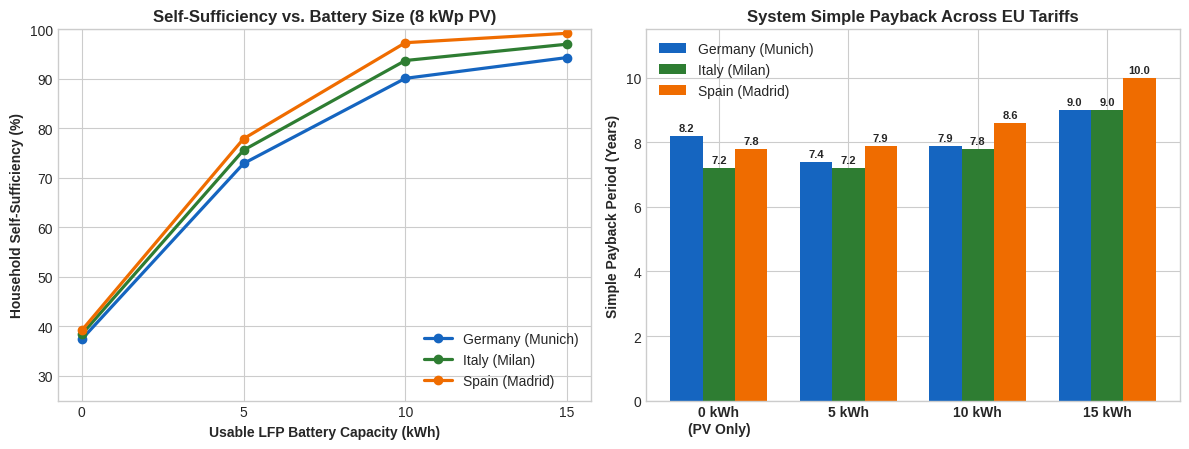

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ==============================================================================
# 1. GENERATE 8,760-HOUR HOUSEHOLD LOAD & WEATHER-REALISTIC PV PROFILES
# ==============================================================================
def build_hourly_profiles(pv_kwp, specific_yield_kwh_kwp, cloudy_days_prob, annual_load_kwh=4500.0, seasonal_amp=0.45):
    rng = np.random.default_rng(42)
    hours = np.arange(8760)
    day = hours // 24
    hod = hours % 24

    # Residential load profile: morning peak (~07:30), evening peak (~19:30), higher winter demand
    seasonal_load = 1.0 + 0.18 * np.cos(2 * np.pi * (day - 15) / 365.0)
    diurnal_load = (
        0.42
        + 0.35 * np.exp(-0.5 * ((hod - 7.5) / 1.5) ** 2)
        + 0.90 * np.exp(-0.5 * ((hod - 19.5) / 2.2) ** 2)
    )
    raw_load = seasonal_load * diurnal_load
    load_kw = raw_load * (annual_load_kwh / raw_load.sum())

    # Multi-day weather fronts (sunny stretches vs. overcast periods)
    daily_weather = np.ones(365)
    for d in range(365):
        if rng.random() < cloudy_days_prob:
            daily_weather[d] = rng.uniform(0.15, 0.45)  # Overcast day
        else:
            daily_weather[d] = rng.uniform(0.85, 1.15)  # Clear / partly sunny day

    daylight = np.where((hod >= 6) & (hod <= 18), np.sin(np.pi * (hod - 6) / 12.0), 0.0)
    seasonal_pv = 1.0 + seasonal_amp * np.sin(2 * np.pi * (day - 80) / 365.0)
    raw_pv = daylight * seasonal_pv * daily_weather[day]
    pv_kw = raw_pv * ((pv_kwp * specific_yield_kwh_kwp) / raw_pv.sum())

    return pv_kw, load_kw


# ==============================================================================
# 2. HOURLY LFP BATTERY DISPATCH ENGINE (95% ROUND-TRIP EFFICIENCY)
# ==============================================================================
def simulate_battery_dispatch(pv_kw, load_kw, battery_kwh, rte=0.95):
    soc = 0.0
    eta = np.sqrt(rte)
    max_power_kw = 0.5 * battery_kwh
    grid_import = 0.0
    grid_export = 0.0

    for pv, load in zip(pv_kw, load_kw):
        net = pv - load
        if net >= 0:
            charge = min(net, max_power_kw, (battery_kwh - soc) / eta) if battery_kwh > 0 else 0.0
            soc += charge * eta
            grid_export += net - charge
        else:
            deficit = -net
            discharge = min(deficit, max_power_kw, soc * eta) if battery_kwh > 0 else 0.0
            soc -= discharge / eta
            grid_import += deficit - discharge

    total_pv = pv_kw.sum()
    total_load = load_kw.sum()
    self_consumed_pv = total_pv - grid_export

    return {
        "Grid Import (kWh)": round(grid_import),
        "Grid Export (kWh)": round(grid_export),
        "Self-Sufficiency (%)": round((1.0 - grid_import / total_load) * 100.0, 1),
        "Self-Consumption (%)": round((self_consumed_pv / total_pv) * 100.0, 1),
    }


# ==============================================================================
# 3. RUN MULTI-COUNTRY & BATTERY SIZING MATRIX (DE, IT, ES)
# ==============================================================================
pv_kwp = 8.0
annual_load = 4500.0
battery_sizes = [0, 5, 10, 15]

markets = [
    {"Country": "Germany (Munich)", "Yield": 1100, "CloudProb": 0.42, "Amp": 0.48, "Import_EUR": 0.36, "Export_EUR": 0.079, "PV_CapEx": 9600, "BESS_EUR_kWh": 480},
    {"Country": "Italy (Milan)",    "Yield": 1300, "CloudProb": 0.30, "Amp": 0.36, "Import_EUR": 0.30, "Export_EUR": 0.095, "PV_CapEx": 9600, "BESS_EUR_kWh": 480},
    {"Country": "Spain (Madrid)",   "Yield": 1600, "CloudProb": 0.18, "Amp": 0.28, "Import_EUR": 0.23, "Export_EUR": 0.065, "PV_CapEx": 8800, "BESS_EUR_kWh": 450},
]

records = []
for m in markets:
    pv_kw, load_kw = build_hourly_profiles(pv_kwp, m["Yield"], m["CloudProb"], annual_load, m["Amp"])
    baseline_bill = annual_load * m["Import_EUR"]

    for cap in battery_sizes:
        sim = simulate_battery_dispatch(pv_kw, load_kw, cap)
        new_bill = sim["Grid Import (kWh)"] * m["Import_EUR"] - sim["Grid Export (kWh)"] * m["Export_EUR"]
        annual_savings = baseline_bill - new_bill
        total_capex = m["PV_CapEx"] + cap * m["BESS_EUR_kWh"]
        payback_yrs = total_capex / annual_savings

        records.append({
            "Market": m["Country"],
            "Battery (kWh)": cap,
            "Self-Sufficiency (%)": sim["Self-Sufficiency (%)"],
            "Self-Consumption (%)": sim["Self-Consumption (%)"],
            "CapEx (€)": total_capex,
            "Annual Savings (€/yr)": round(annual_savings),
            "Simple Payback (yrs)": round(payback_yrs, 1),
        })

df_results = pd.DataFrame(records)
print("=== RESIDENTIAL 8 kWp PV + LFP BESS SIZING & PAYBACK ACROSS EU MARKETS ===")
print(df_results.to_string(index=False))


# ==============================================================================
# 4. PORTFOLIO VISUALIZATION (SELF-SUFFICIENCY CURVE & PAYBACK COMPARISON)
# ==============================================================================
plt.style.use("seaborn-v0_8-whitegrid")
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.6))

colors = {"Germany (Munich)": "#1565c0", "Italy (Milan)": "#2e7d32", "Spain (Madrid)": "#ef6c00"}

# Left Plot: Self-Sufficiency vs. Battery Capacity
for country, grp in df_results.groupby("Market", sort=False):
    ax1.plot(grp["Battery (kWh)"], grp["Self-Sufficiency (%)"], marker="o", linewidth=2.3, label=country, color=colors[country])
ax1.set_xticks(battery_sizes)
ax1.set_xlabel("Usable LFP Battery Capacity (kWh)", fontweight="bold")
ax1.set_ylabel("Household Self-Sufficiency (%)", fontweight="bold")
ax1.set_ylim(25, 100)
ax1.set_title("Self-Sufficiency vs. Battery Size (8 kWp PV)", fontweight="bold")
ax1.legend(loc="lower right")

# Right Plot: Simple Payback Period by Battery Size & Country
x = np.arange(len(battery_sizes))
width = 0.25
for idx, (country, grp) in enumerate(df_results.groupby("Market", sort=False)):
    bars = ax2.bar(x + (idx - 1) * width, grp["Simple Payback (yrs)"], width=width, label=country, color=colors[country])
    for b in bars:
        ax2.annotate(f"{b.get_height():.1f}", (b.get_x() + b.get_width() / 2, b.get_height() + 0.15),
                     ha="center", fontsize=8, fontweight="bold")

ax2.set_xticks(x)
ax2.set_xticklabels([f"{c} kWh" if c > 0 else "0 kWh\n(PV Only)" for c in battery_sizes], fontweight="bold")
ax2.set_ylabel("Simple Payback Period (Years)", fontweight="bold")
ax2.set_ylim(0, 11.5)
ax2.set_title("System Simple Payback Across EU Tariffs", fontweight="bold")
ax2.legend(loc="upper left")

plt.tight_layout()
plt.savefig("pv_bess_eu_payback.png", dpi=300)
plt.show()